In [2]:
# Question 7.1&7.2 

import torch
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Chargement et normalisation
ds = fetch_california_housing()
X_raw = ds.data
y_raw = ds.target.reshape(-1, 1)
sx, sy = StandardScaler(), StandardScaler()
X = torch.tensor(sx.fit_transform(X_raw), dtype=torch.float32)
y = torch.tensor(sy.fit_transform(y_raw), dtype=torch.float32)

# Séparation train/test
Xtrain, Xtest, Ytrain, Ytest = train_test_split(X, y, test_size=0.2, random_state=42)

# Définition du modèle linéaire
model = torch.nn.Linear(Xtrain.shape[1], 1)

criterion = torch.nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-2)

# Boucle d’apprentissage
n_epochs = 1000
for epoch in range(n_epochs):
    # Forward
    Yhat = model(Xtrain)
    loss = criterion(Yhat, Ytrain)

    # Backward
    optimizer.zero_grad()   
    loss.backward()         
    optimizer.step()        

    if epoch % 100 == 0:
        with torch.no_grad():
            loss_test = criterion(model(Xtest), Ytest)
        print(f"Epoch {epoch:4d} | Train Loss = {loss.item():.4f} | Test Loss = {loss_test.item():.4f}")

# Résultats finaux
with torch.no_grad():
    W_norm = torch.norm(model.weight).item()
    b_final = model.bias.item()
print(f"\nNorme de W : {W_norm:.3f}, b final = {b_final:.3f}")


Epoch    0 | Train Loss = 0.8605 | Test Loss = 0.7833
Epoch  100 | Train Loss = 0.4831 | Test Loss = 0.4921
Epoch  200 | Train Loss = 0.4475 | Test Loss = 0.4552
Epoch  300 | Train Loss = 0.4314 | Test Loss = 0.4389
Epoch  400 | Train Loss = 0.4202 | Test Loss = 0.4285
Epoch  500 | Train Loss = 0.4119 | Test Loss = 0.4215
Epoch  600 | Train Loss = 0.4059 | Test Loss = 0.4169
Epoch  700 | Train Loss = 0.4014 | Test Loss = 0.4141
Epoch  800 | Train Loss = 0.3982 | Test Loss = 0.4123
Epoch  900 | Train Loss = 0.3958 | Test Loss = 0.4114

Norme de W : 1.205, b final = -0.001


In [3]:
#Question 7.3

import torch
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from torch.utils.tensorboard import SummaryWriter
from sklearn.preprocessing import StandardScaler

# Chargement et normalisation du dataset
ds = fetch_california_housing()
X_raw = ds.data
y_raw = ds.target.reshape(-1, 1)
sx = StandardScaler()
sy = StandardScaler()
X = torch.tensor(sx.fit_transform(X_raw), dtype=torch.float32)
y = torch.tensor(sy.fit_transform(y_raw), dtype=torch.float32)

# Séparation train/test
Xtrain, Xtest, Ytrain, Ytest = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialisation des paramètres
n_features = Xtrain.shape[1]
W = torch.randn(n_features, 1, requires_grad=True)
b = torch.randn(1, requires_grad=True)
eta = 1e-2       
n_epochs = 1000

# Initialisation de TensorBoard 
writer = SummaryWriter("runs/california_batch")

#  Boucle d’apprentissage
for epoch in range(n_epochs):
    # Prédiction : f(X) = XW + b
    Yhat = Xtrain @ W + b
    loss = torch.mean((Yhat - Ytrain) ** 2)
    loss.backward()

    with torch.no_grad():
        W -= eta * W.grad
        b -= eta * b.grad

    W.grad.zero_()
    b.grad.zero_()

    if epoch % 100 == 0:
        Ytest_hat = Xtest @ W + b
        loss_test = torch.mean((Ytest_hat - Ytest) ** 2)

        print(f"Epoch {epoch:3d} | Train Loss = {loss.item():.4f} | Test Loss = {loss_test.item():.4f}")
        writer.add_scalar("Loss/train", loss.item(), epoch)
        writer.add_scalar("Loss/test", loss_test.item(), epoch)

writer.close()

print(f"Norme de W : {W.norm().item():.3f}, b final = {b.item():.3f}")

!tensorboard --logdir=runs


Epoch   0 | Train Loss = 6.0293 | Test Loss = 5.7274
Epoch 100 | Train Loss = 0.5800 | Test Loss = 0.5756
Epoch 200 | Train Loss = 0.4747 | Test Loss = 0.4810
Epoch 300 | Train Loss = 0.4508 | Test Loss = 0.4590
Epoch 400 | Train Loss = 0.4345 | Test Loss = 0.4438
Epoch 500 | Train Loss = 0.4225 | Test Loss = 0.4333
Epoch 600 | Train Loss = 0.4137 | Test Loss = 0.4262
Epoch 700 | Train Loss = 0.4073 | Test Loss = 0.4214
Epoch 800 | Train Loss = 0.4025 | Test Loss = 0.4183
Epoch 900 | Train Loss = 0.3990 | Test Loss = 0.4164
Norme de W : 1.120, b final = -0.000
TensorFlow installation not found - running with reduced feature set.
Serving TensorBoard on localhost; to expose to the network, use a proxy or pass --bind_all
TensorBoard 2.20.0 at http://localhost:6007/ (Press CTRL+C to quit)
^C


Descente stochastique terminée.
Descente mini-batch terminée.


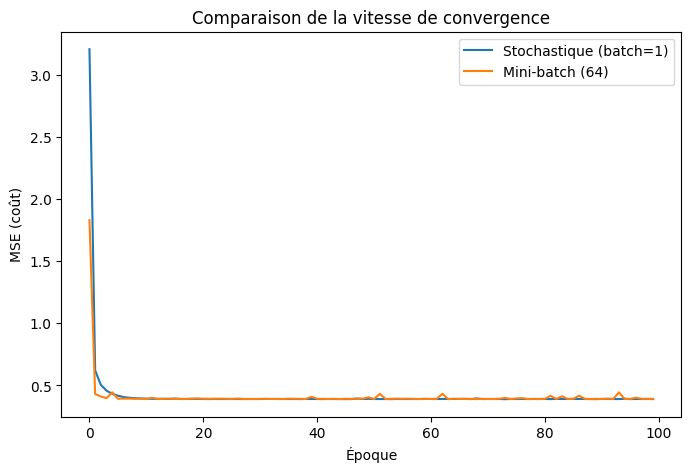

In [6]:
#Question 7.4
# === Descente de gradient stochastique et mini-batch ===
import torch
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Chargement et normalisation du dataset
ds = fetch_california_housing()
sx, sy = StandardScaler(), StandardScaler()
X = torch.tensor(sx.fit_transform(ds.data), dtype=torch.float32)
Y = torch.tensor(sy.fit_transform(ds.target.reshape(-1, 1)), dtype=torch.float32)
Xtrain, Xtest, Ytrain, Ytest = train_test_split(X, Y, test_size=0.2, random_state=42)

# Paramètres
n_features = Xtrain.shape[1]
n_epochs = 100
batch_size = 64  # taille du mini-batch

# Descente de gradient stochastique 
W = torch.randn(n_features, 1, requires_grad=True)
b = torch.randn(1, requires_grad=True)
optimizer_sgd = torch.optim.SGD([W, b], lr=1e-4)
loss_sgd = []

for epoch in range(n_epochs):
    perm = torch.randperm(Xtrain.size(0))
    total_loss = 0
    for i in perm:
        x_i = Xtrain[i].unsqueeze(0).requires_grad_(True)
        y_i = Ytrain[i].unsqueeze(0)

        y_pred = x_i @ W + b
        loss = torch.mean((y_pred - y_i) ** 2)

        optimizer_sgd.zero_grad() 
        loss.backward()
        optimizer_sgd.step()     
        
        total_loss += loss.item()

    loss_sgd.append(total_loss / len(perm))

print("Descente stochastique terminée.")

# Descente de gradient mini-batch
W = torch.randn(n_features, 1, requires_grad=True)
b = torch.randn(1, requires_grad=True)
optimizer_mb = torch.optim.SGD([W, b], lr=eta)
loss_minibatch = []

for epoch in range(n_epochs):
    perm = torch.randperm(Xtrain.size(0))
    total_loss = 0
    for i in range(0, Xtrain.size(0), batch_size):
        idx = perm[i:i + batch_size]
        x_batch = Xtrain[idx]
        y_batch = Ytrain[idx]

        y_pred = x_batch @ W + b
        loss = torch.mean((y_pred - y_batch) ** 2)

        optimizer_mb.zero_grad()
        loss.backward()
        optimizer_mb.step()

        total_loss += loss.item()

    loss_minibatch.append(total_loss / (Xtrain.size(0) // batch_size))

print("Descente mini-batch terminée.")


# Comparaison graphique 
plt.figure(figsize=(8,5))
plt.plot(loss_sgd, label="Stochastique (batch=1)")
plt.plot(loss_minibatch, label="Mini-batch (64)")
plt.xlabel("Époque")
plt.ylabel("MSE (coût)")
plt.title("Comparaison de la vitesse de convergence")
plt.legend()
plt.show()